In [1]:
!mamba install scikit-learn
!mamba install pandas numpy
%pip install pandas numpy
!pip install scikit-learn matplotlib pandas numpy

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 2.334 seconds
  Name                Version    Build                Channel
---------------------------------------------------------------------------
+ brotli-python       1.2.0      py313ha26e73d_2      emscripten-forge-4x
+ certifi             2026.7.22  pyhd8ed1ab_0         conda-forge
+ charset-normalizer  3.5.1      pyhd8ed1ab_0         conda-forge
+ idna                3.20       pyh5ded981_0         conda-forge
+ joblib              1.6.0      py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.27.1     pyh5ded981_0         conda-forge
+ pysocks             1.7.1      py313h1804a44_3      emscripten-forge-4x
+ requests            2.34.2     pyhcf101f3_0         conda-forge
+ scikit-learn        1.9.0      np23py313hb9816c2_0  emscripten-forge-4x
+ setuptools          84.0.0

--- Baseline Model: Logistic Regression ---
              precision    recall  f1-score   support

    Retained       0.84      0.71      0.76       173
    Inactive       0.51      0.69      0.59        77

    accuracy                           0.70       250
   macro avg       0.67      0.70      0.68       250
weighted avg       0.74      0.70      0.71       250


--- Tree-Based Model: Decision Tree ---
              precision    recall  f1-score   support

    Retained       0.81      0.64      0.72       173
    Inactive       0.45      0.66      0.54        77

    accuracy                           0.65       250
   macro avg       0.63      0.65      0.63       250
weighted avg       0.70      0.65      0.66       250



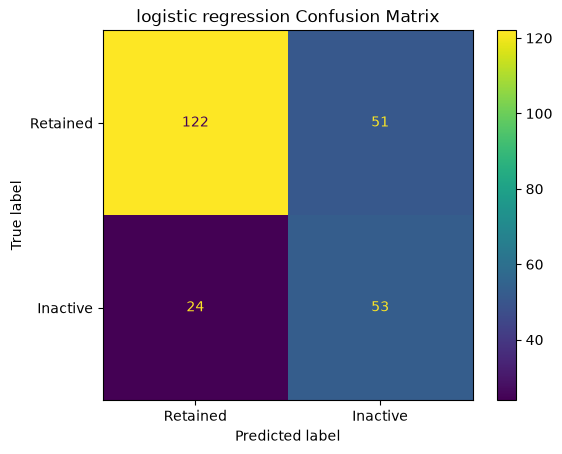

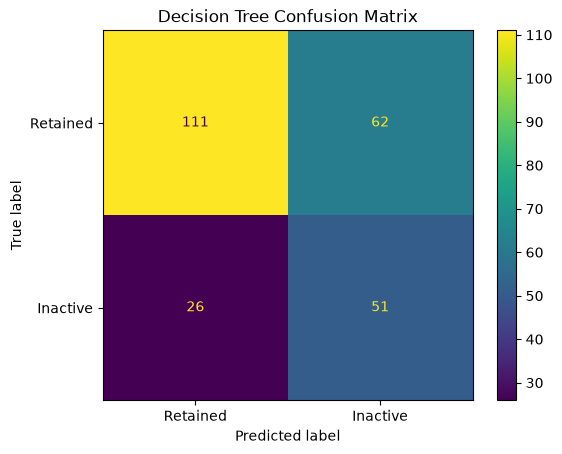

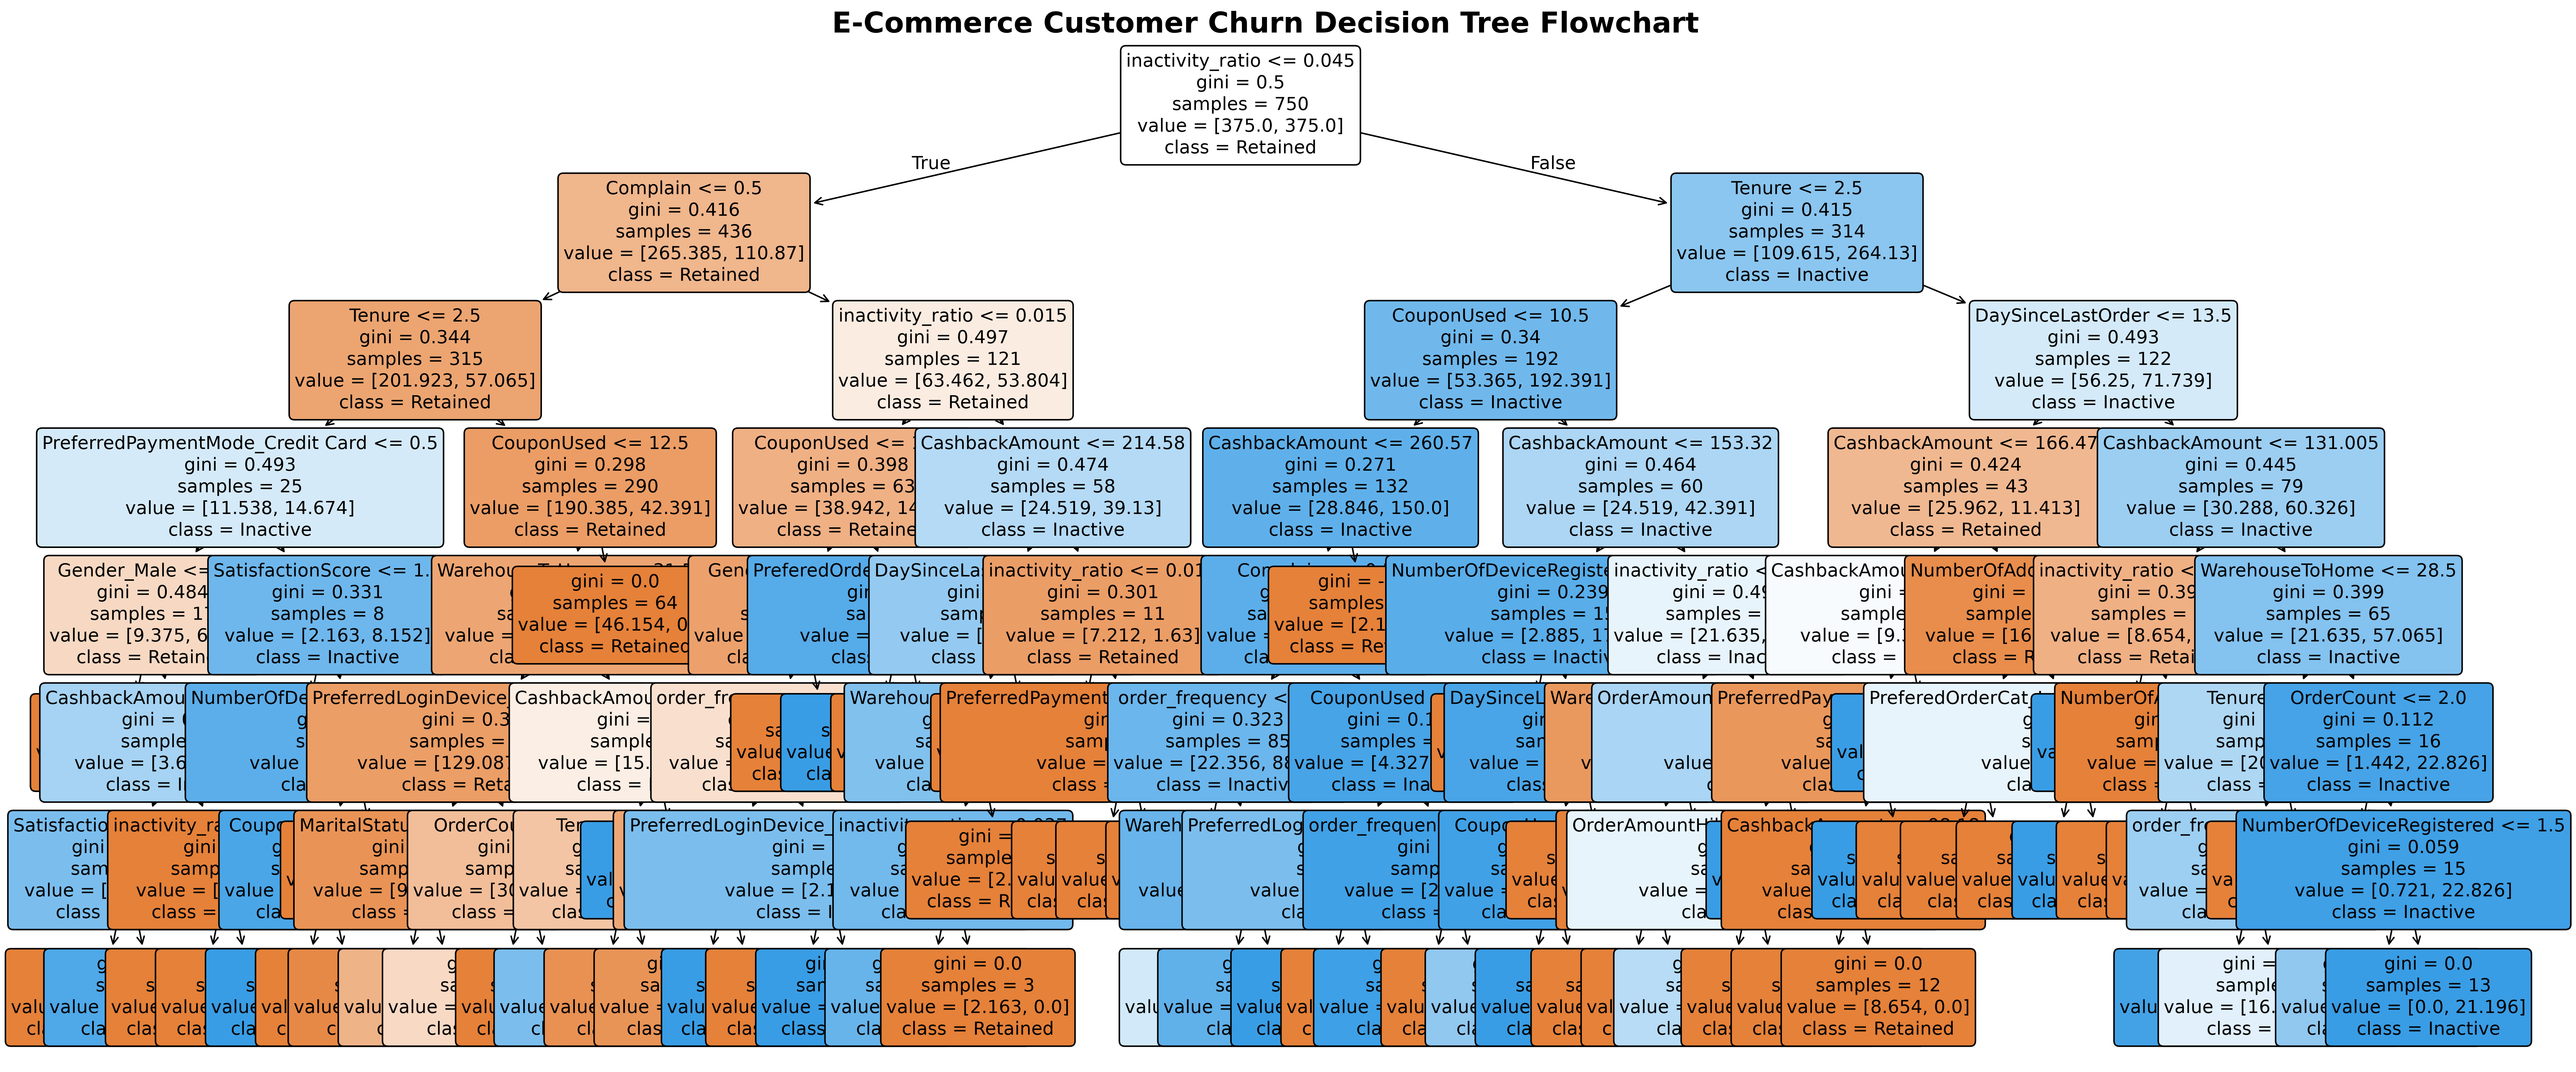

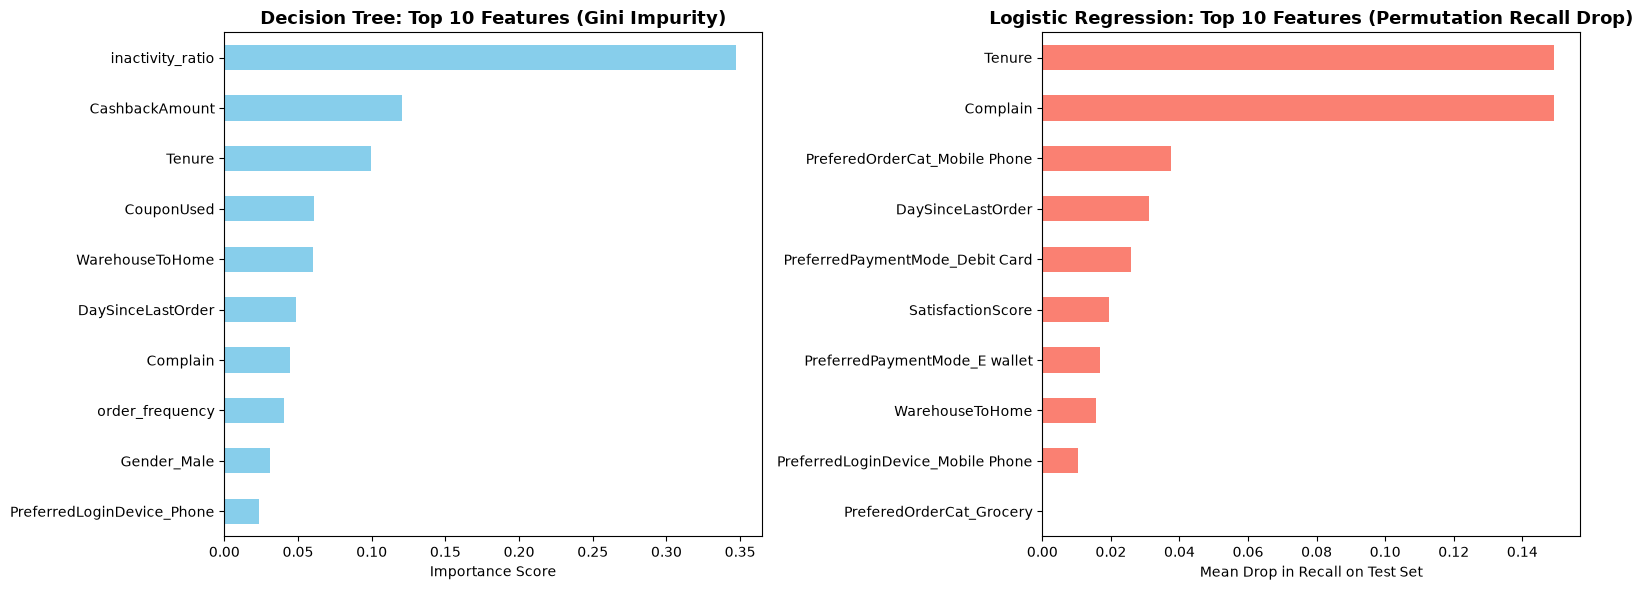


--- Top 5 inactive Drivers: Decision Tree ---
inactivity_ratio    0.347457
CashbackAmount      0.120298
Tenure              0.099348
CouponUsed          0.060991
WarehouseToHome     0.059868

--- Top 5 inactive Drivers: Logistic Regression (Permutation Importance) ---
Tenure                             0.149351
Complain                           0.149351
PreferedOrderCat_Mobile Phone      0.037662
DaySinceLastOrder                  0.031169
PreferredPaymentMode_Debit Card    0.025974


In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.inspection import permutation_importance
#  Load Data
df = pd.read_csv("E_Commerce_Dataset.csv")
df = df.drop(columns=["CustomerID"])

#  Feature Engineering
df["inactivity_ratio"] = df["DaySinceLastOrder"] / (df["Tenure"] * 30.0 + 1e-5)
df["order_frequency"] = df["OrderCount"] / (df["Tenure"] + 1e-5)

# Separate features (X) and target (y)
df_encoded = pd.get_dummies(df, drop_first=True)
X = df_encoded.drop(columns=["Churn"])
y = df_encoded["Churn"]

# Stratified Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Fill missing values using training set median
train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# 4. Build Baseline Pipeline: Scaler -> Logistic Regression
lr_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(class_weight="balanced",max_iter=1000, random_state=42)),
    ]
)

# Train Baseline Pipeline
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)

#  Build Decision Tree Pipeline (No scaler required for Trees)
dt_pipeline = Pipeline(
    [("classifier", DecisionTreeClassifier(class_weight="balanced",max_depth=7, random_state=42))]
)

# Train Decision Tree Pipeline
dt_pipeline.fit(X_train, y_train)
y_pred_dt = dt_pipeline.predict(X_test)

# Detailed Evaluation & Comparison
target_names = ["Retained", "Inactive"]

print("--- Baseline Model: Logistic Regression ---")
print(classification_report(y_test, y_pred_lr, target_names=target_names))

print("\n--- Tree-Based Model: Decision Tree ---")
print(classification_report(y_test, y_pred_dt, target_names=target_names))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_lr, display_labels=target_names
)
plt.title("logistic regression Confusion Matrix")
plt.savefig("lr_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


# Plot Confusion Matrix for Decision Tree
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_dt, display_labels=target_names
)
plt.title("Decision Tree Confusion Matrix")
plt.savefig("dt_confusion_matrix.png", dpi=300, bbox_inches="tight") 

#  Plot Decision Tree Flowchart
plt.figure(figsize=(24, 10), dpi=300)
plot_tree(
    dt_pipeline.named_steps["classifier"],
    feature_names=X_train.columns,
    class_names=target_names,
    filled=True,
    rounded=True,
    fontsize=12,
)

plt.title(
    "E-Commerce Customer Churn Decision Tree Flowchart",
    fontsize=19,
    fontweight="bold",
)
plt.tight_layout()
plt.savefig("decision_tree_flowchart.png", dpi=300, bbox_inches="tight")
plt.show()
dt_model = dt_pipeline.named_steps["classifier"]
dt_importances = pd.Series(
    dt_model.feature_importances_, index=X_train.columns
).sort_values(ascending=True)

# Logistic Regression Permutation Importance (Test Set Recall Drop) ---
perm_result = permutation_importance(
    lr_pipeline, X_test, y_test, scoring="recall", n_repeats=10, random_state=42
)
lr_importances = pd.Series(
    perm_result.importances_mean, index=X_train.columns
).sort_values(ascending=True)

# Plot Side-by-Side Comparison (Top 10 Features) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Decision Tree Gini Importance
dt_importances.tail(10).plot(kind="barh", ax=axes[0], color="skyblue")
axes[0].set_title(
    "Decision Tree: Top 10 Features (Gini Impurity)", fontsize=13, fontweight="bold"
)
axes[0].set_xlabel("Importance Score")

# Subplot 2: Logistic Regression Permutation Importance
lr_importances.tail(10).plot(kind="barh", ax=axes[1], color="salmon")
axes[1].set_title(
    "Logistic Regression: Top 10 Features (Permutation Recall Drop)",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_xlabel("Mean Drop in Recall on Test Set")

plt.tight_layout()
plt.savefig("feature_importances_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

# Print Top 5 drivers for quick executive notes
print("\n--- Top 5 inactive Drivers: Decision Tree ---")
print(dt_importances.tail(5).iloc[::-1].to_string())

print("\n--- Top 5 inactive Drivers: Logistic Regression (Permutation Importance) ---")
print(lr_importances.tail(5).iloc[::-1].to_string())